# AI4CM - Part 1
## RFM and behavioural clustering


Repository update (November 2026): data paths now use the folders documented in `data/README.md`. Saved results come from the final course notebook. Raw datasets are obtained separately from their publishers. Parallel training in Part 3 is limited to one worker to reduce memory use. The numerical experiments and hyperparameter grids are otherwise retained. Some interpretations have been qualified where the original text overstated generalization or independence.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

from pathlib import Path

def find_repository_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "environment.yml").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Open the notebook from the repository root or its project subfolder.")

ROOT = find_repository_root()
DATA_PATH = ROOT / "data/rfm/marketing_campaign.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Missing data/rfm/marketing_campaign.csv; see data/README.md")
ASSET_DIR = ROOT / "outputs/segmentation"
ASSET_DIR.mkdir(parents=True, exist_ok=True)


Using dataset: ../marketing_campaign.csv


## Task A - Data audit and quality

I start from the raw file and audit the fields before changing them. The important point is to separate three cases:

1. actual data errors, which should be corrected or imputed;
2. rare but plausible customers, which should not be deleted just because they are valuable or old;
3. small inconsistencies, which should be documented if there is not enough evidence to repair them safely.


In [2]:
raw = pd.read_csv(DATA_PATH, sep=None, engine="python", encoding="utf-8-sig")

print("Raw shape:", raw.shape)
print("Unique IDs:", raw["ID"].is_unique)
print("Duplicate full rows, including ID:", raw.duplicated().sum())
print("Duplicate profiles, excluding ID:", raw.drop(columns="ID").duplicated().sum())

missing = raw.isna().sum()
display(missing[missing > 0].rename("missing_count").to_frame())

audit_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(dropna=False)
})
display(audit_summary)


Raw shape: (2240, 27)
Unique IDs: True
Duplicate full rows, including ID: 0
Duplicate profiles, excluding ID: 182


,missing_count
Income,24


,dtype,non_null,missing,unique
ID,int64,2240,0,2240
Year_Birth,int64,2240,0,59
Education,str,2240,0,5
Marital_Status,str,2240,0,8
Income,float64,2216,24,1975
Kidhome,int64,2240,0,3
Teenhome,int64,2240,0,3
Dt_Customer,str,2240,0,663
Recency,int64,2240,0,100
MntWines,int64,2240,0,776


### Structural checks

The standard audit finds the main issues, but it is not enough. Before cleaning, I also check ranges and consistency rules that come from the data dictionary.


In [3]:
# Parse dates only for the audit; the cleaned dataframe is built in the next cell.
dates = pd.to_datetime(raw["Dt_Customer"], errors="coerce")

binary_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Complain", "Response"]
invalid_binary = {col: sorted(set(raw[col].dropna()) - {0, 1}) for col in binary_cols}

spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
channel_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

channel_frequency = raw[channel_cols].sum(axis=1)
total_spending_raw = raw[spending_cols].sum(axis=1)

checks = pd.Series({
    "date_parse_errors": dates.isna().sum(),
    "min_customer_date": dates.min(),
    "max_customer_date": dates.max(),
    "invalid_binary_columns": sum(len(v) > 0 for v in invalid_binary.values()),
    "negative_spending_cells": int((raw[spending_cols] < 0).sum().sum()),
    "negative_purchase_count_cells": int((raw[channel_cols + ["NumDealsPurchases", "NumWebVisitsMonth"]] < 0).sum().sum()),
    "positive_spend_but_zero_channel_purchases": int(((total_spending_raw > 0) & (channel_frequency == 0)).sum()),
    "discount_purchases_above_channel_frequency": int((raw["NumDealsPurchases"] > channel_frequency).sum()),
    "web_purchases_with_zero_web_visits": int(((raw["NumWebPurchases"] > 0) & (raw["NumWebVisitsMonth"] == 0)).sum())
})

display(checks.rename("audit_value").to_frame())
print("Invalid binary values:", invalid_binary)

display(raw[["Education", "Marital_Status"]].agg(lambda s: s.value_counts(dropna=False).to_dict()).T)


,audit_value
date_parse_errors,0
min_customer_date,2012-07-30 00:00:00
max_customer_date,2014-06-29 00:00:00
invalid_binary_columns,0
negative_spending_cells,0
negative_purchase_count_cells,0
positive_spend_but_zero_channel_purchases,6
discount_purchases_above_channel_frequency,3
web_purchases_with_zero_web_visits,6


Invalid binary values: {'AcceptedCmp1': [], 'AcceptedCmp2': [], 'AcceptedCmp3': [], 'AcceptedCmp4': [], 'AcceptedCmp5': [], 'Complain': [], 'Response': []}


Education         {'Graduation': 1127, 'PhD': 486, 'Master': 370...
Marital_Status    {'Married': 864, 'Together': 580, 'Single': 48...
dtype: object

In [4]:
# IQR outlier audit. This is an audit table, not an automatic deletion rule.
# In marketing datasets, high spenders and deal-heavy customers are often the signal we need.
audit_reference_year = int(dates.dt.year.max())
outlier_base = raw.copy()
outlier_base["Age_2014"] = audit_reference_year - outlier_base["Year_Birth"]
outlier_base["Total_Spending_raw"] = total_spending_raw
outlier_base["Frequency_raw"] = channel_frequency

outlier_cols = [
    "Age_2014", "Income", "Recency", "Total_Spending_raw", "Frequency_raw",
    "NumWebVisitsMonth", "NumDealsPurchases", *spending_cols, *channel_cols,
]

outlier_rows = []
for col in outlier_cols:
    s = outlier_base[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "column": col,
        "q1": q1,
        "q3": q3,
        "low_bound": low,
        "high_bound": high,
        "low_outliers": int((s < low).sum()),
        "high_outliers": int((s > high).sum()),
        "max": s.max(),
    })

outlier_audit = pd.DataFrame(outlier_rows)
display(outlier_audit.round(2))


,column,q1,q3,low_bound,high_bound,low_outliers,high_outliers,max
0,Age_2014,37.00,55.00,10.00,82.00,0,3,121.00
1,Income,"35,303.00","68,522.00","-14,525.50","118,350.50",0,8,"666,666.00"
2,Recency,24.00,74.00,-51.00,149.00,0,0,99.00
3,Total_Spending_raw,68.75,"1,045.50","-1,396.38","2,510.62",0,3,"2,525.00"
4,Frequency_raw,6.00,18.00,-12.00,36.00,0,0,32.00
5,NumWebVisitsMonth,3.00,7.00,-3.00,13.00,0,8,20.00
6,NumDealsPurchases,1.00,3.00,-2.00,6.00,0,86,15.00
7,MntWines,23.75,504.25,-697.00,"1,225.00",0,35,"1,493.00"
8,MntFruits,1.00,33.00,-47.00,81.00,0,227,199.00
9,MntMeatProducts,16.00,232.00,-308.00,556.00,0,175,"1,725.00"


### Outlier reading

The IQR table is used to separate data errors from marketing signal. I correct the impossible ages and the isolated income value above 300,000 because they are not credible customer profiles. I do not cap all high product spending, deal purchases or catalog purchases just because IQR flags them: those observations are plausible high-value or deal-oriented customers, and removing them would erase the behavioural signal needed for segmentation.

So the cleaning rule is conservative: fix clear data-entry errors, document heavy tails, and preserve plausible commercial extremes.

### Cleaning strategy

- Duplicate profiles: 182 records are identical on every attribute except `ID`. With a unique ID they are not technical duplicates, but for this teaching dataset they are repeated customer profiles. I remove them before any median or percentile is computed. After category harmonisation, one more duplicate appears because `Alone` is collapsed into `Single`; I remove that residual double-count as well.
- Income missing values: imputed with the median after deduplication. The median is safer than the mean because income is skewed.
- Age errors: the reference year is the latest enrollment year in the data, 2014. Birth years producing age above 100 are treated as data-entry errors, not as old customers.
- Income outlier: I correct only the isolated value above 300,000. I do not cap the whole top 1%, because high-income customers are meaningful for marketing.
- Education: `2n Cycle` is kept as its own valid category. Merging it into `Master` would be arbitrary.
- Marital status: `Alone` is mapped to `Single`; `Absurd` and `YOLO` are kept as `Other` rather than forced into a real marital status.

The small purchase-count inconsistencies are documented but not manually repaired. The six records with positive spending and zero channel purchases are retained: together they account for only EUR 42, about 0.003% of total spending, and there is no reliable evidence to impute the missing channel. Keeping them is safer than inventing a channel or deleting valid low-value spend.


In [5]:
df = raw.copy()
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], errors="coerce")
df = df.set_index("ID")

print("Duplicate profiles before cleaning:", df.duplicated().sum())
df = df.drop_duplicates().copy()

median_income = df["Income"].median()
df["Income"] = df["Income"].fillna(median_income)

reference_year = int(df["Dt_Customer"].dt.year.max())
df["Age"] = reference_year - df["Year_Birth"]

impossible_age_mask = df["Age"] > 100
print("Impossible ages (>100):", int(impossible_age_mask.sum()))
df.loc[impossible_age_mask, "Age"] = np.nan
df["Age"] = df["Age"].fillna(df["Age"].median())

extreme_income_mask = df["Income"] > 300_000
print("Extreme income values corrected:", int(extreme_income_mask.sum()))
df.loc[extreme_income_mask, "Income"] = np.nan
df["Income"] = df["Income"].fillna(df["Income"].median())

df["Marital_Status"] = df["Marital_Status"].replace({
    "Alone": "Single",
    "Absurd": "Other",
    "YOLO": "Other"
})

post_category_duplicates = int(df.duplicated().sum())
print("Duplicate profiles after category harmonisation:", post_category_duplicates)
df = df.drop_duplicates().copy()

# Core marketing metrics used throughout the notebook.
df["Total_Spending"] = df[spending_cols].sum(axis=1)
df["Frequency"] = df[channel_cols].sum(axis=1)
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]
df["Has_Children"] = np.where(df["Total_Children"] > 0, "With children", "No children")

clean_checks = pd.Series({
    "clean_rows": len(df),
    "missing_values": int(df.isna().sum().sum()),
    "residual_duplicate_profiles": int(df.duplicated().sum()),
    "min_age": df["Age"].min(),
    "max_age": df["Age"].max(),
    "median_income_used": median_income,
    "max_income_after_cleaning": df["Income"].max(),
    "total_spending": df["Total_Spending"].sum()
})

display(clean_checks.rename("value").to_frame())
display(df[["Year_Birth", "Age", "Income", "Total_Spending", "Frequency"]].describe().T)
display(df[["Education", "Marital_Status"]].agg(lambda s: s.value_counts().to_dict()).T)


Duplicate profiles before cleaning: 182
Impossible ages (>100): 3
Extreme income values corrected: 1
Duplicate profiles after category harmonisation: 1


,value
clean_rows,"2,057.00"
missing_values,0.00
residual_duplicate_profiles,0.00
min_age,18.00
max_age,74.00
median_income_used,"51,533.00"
max_income_after_cleaning,"162,397.00"
total_spending,"1,247,554.00"


,count,mean,std,min,25%,50%,75%,max
Year_Birth,"2,057.00","1,968.78",11.97,"1,893.00","1,959.00","1,970.00","1,977.00","1,996.00"
Age,"2,057.00",45.12,11.65,18.00,37.00,44.00,55.00,74.00
Income,"2,057.00","52,057.96","21,460.32","1,730.00","35,704.00","51,533.00","68,148.00","162,397.00"
Total_Spending,"2,057.00",606.49,602.88,5.00,69.00,397.00,"1,047.00","2,525.00"
Frequency,"2,057.00",12.53,7.19,0.00,6.00,12.00,18.00,32.00


Education         {'Graduation': 1029, 'PhD': 450, 'Master': 341...
Marital_Status    {'Married': 795, 'Together': 521, 'Single': 45...
dtype: object

## Task B - Exploratory data analysis

The EDA has three goals: identify what drives spending, understand channel usage, and extract one campaign insight that is useful for communication.


,Age,Income,Kidhome,Teenhome,Total_Children,Total_Spending
Age,1.00,0.22,-0.27,0.39,0.08,0.16
Income,0.22,1.00,-0.57,0.05,-0.38,0.85
Kidhome,-0.27,-0.57,1.00,-0.06,0.67,-0.62
Teenhome,0.39,0.05,-0.06,1.00,0.69,-0.06
Total_Children,0.08,-0.38,0.67,0.69,1.00,-0.49
Total_Spending,0.16,0.85,-0.62,-0.06,-0.49,1.00


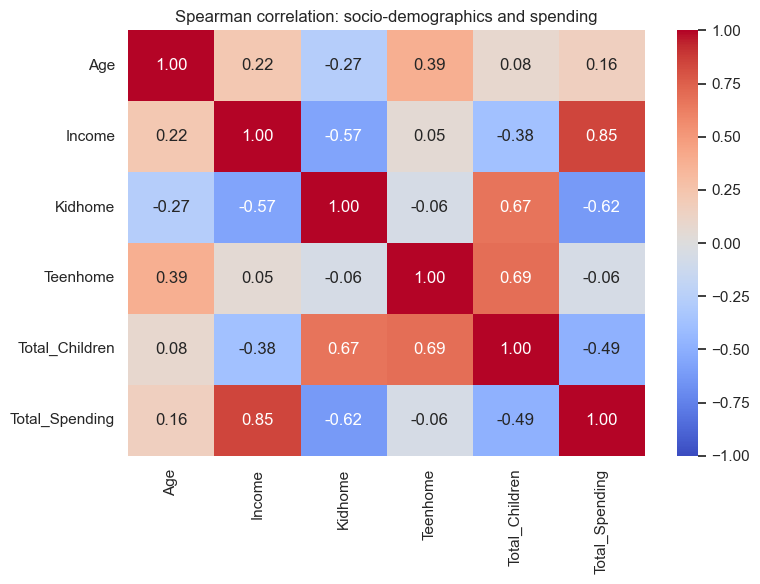

In [6]:
demo_features = ["Age", "Income", "Kidhome", "Teenhome", "Total_Children", "Total_Spending"]
corr_spearman = df[demo_features].corr(method="spearman")

display(corr_spearman.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation: socio-demographics and spending")
plt.tight_layout()
fig.savefig(ASSET_DIR / "01_spearman_correlation.png", dpi=180, bbox_inches="tight")
plt.show()


Spearman is used because children counts are ordinal and the relationship with spending is monotonic rather than perfectly linear. The main result is clear: income is the strongest positive driver of spend, while households with young children spend less on this product mix.


,purchase_count
Store,11872
Web,8432
Catalog,5476


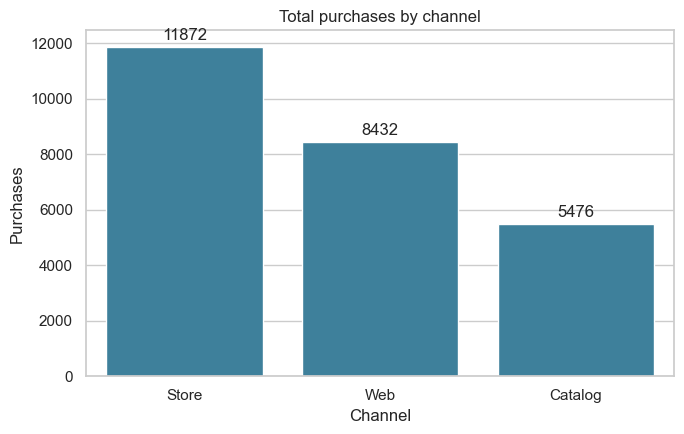

In [7]:
channel_sums = df[channel_cols].sum().rename(index={
    "NumWebPurchases": "Web",
    "NumCatalogPurchases": "Catalog",
    "NumStorePurchases": "Store"
}).sort_values(ascending=False)

display(channel_sums.rename("purchase_count").to_frame())

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=channel_sums.index, y=channel_sums.values, ax=ax, color="#2E86AB")
ax.set_title("Total purchases by channel")
ax.set_xlabel("Channel")
ax.set_ylabel("Purchases")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.tight_layout()
fig.savefig(ASSET_DIR / "02_channel_purchases.png", dpi=180, bbox_inches="tight")
plt.show()


Store is the largest channel by number of purchases, followed by Web and then Catalog. This is an activity view, not a profitability view: the dataset does not give revenue by channel.


,Web,Catalog,Store,customers
Total_Children,,,,
0,4.45,4.79,7.30,577
1,4.29,2.14,5.56,1044
2,3.23,1.11,4.29,388
3,2.73,1.04,3.96,48


Catalog drop from 0 to 3 children: 78.3%
Web drop from 0 to 3 children: 38.7%


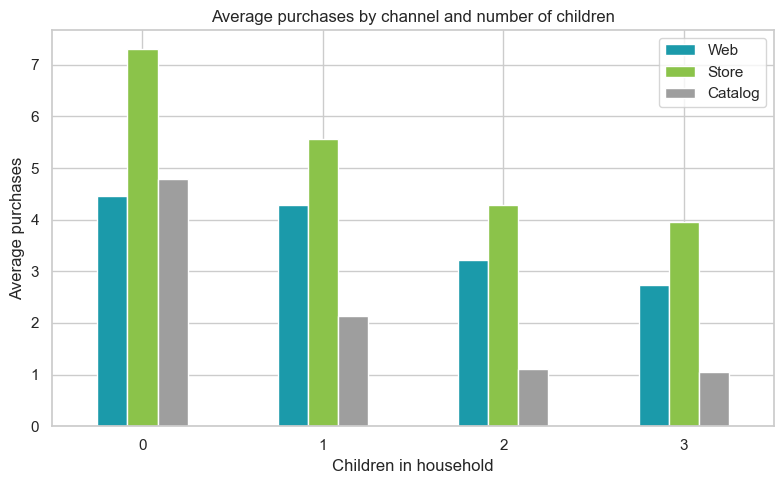

In [8]:
children_channel = df.groupby("Total_Children")[channel_cols].mean().rename(columns={
    "NumWebPurchases": "Web",
    "NumCatalogPurchases": "Catalog",
    "NumStorePurchases": "Store"
})
children_counts = df["Total_Children"].value_counts().sort_index().rename("customers")
children_profile = children_channel.join(children_counts)

display(children_profile.round(2))

catalog_drop = 1 - children_channel.loc[3, "Catalog"] / children_channel.loc[0, "Catalog"]
web_drop = 1 - children_channel.loc[3, "Web"] / children_channel.loc[0, "Web"]
print(f"Catalog drop from 0 to 3 children: {catalog_drop:.1%}")
print(f"Web drop from 0 to 3 children: {web_drop:.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
children_channel[["Web", "Store", "Catalog"]].plot(kind="bar", ax=ax, color=["#1B9AAA", "#8BC34A", "#9E9E9E"])
ax.set_title("Average purchases by channel and number of children")
ax.set_xlabel("Children in household")
ax.set_ylabel("Average purchases")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
fig.savefig(ASSET_DIR / "03_children_channels.png", dpi=180, bbox_inches="tight")
plt.show()


### Hidden trend for communication

Families with children buy less overall, but the channel mix is the useful part. Catalog drops much faster than Web as the number of children increases. The practical campaign idea is a Web-first convenience offer for parents: less catalog effort, more online bundles, reminders and fast-reorder messages.

This is not a claim that children cause lower spend. Income and children are related in this dataset, so the safe marketing interpretation is channel preference among family households, not a causal statement about family size.

One important caution: the group with three children is small (48 customers after cleaning). I use the 0-to-3-children comparison as a directional communication insight, not as a precise population estimate.

Has_Children,No children,With children
Income_Quartile,,
Q1,134.90,72.80
Q2,490.30,218.60
Q3,"1,065.30",673.60
Q4,"1,459.00","1,138.40"


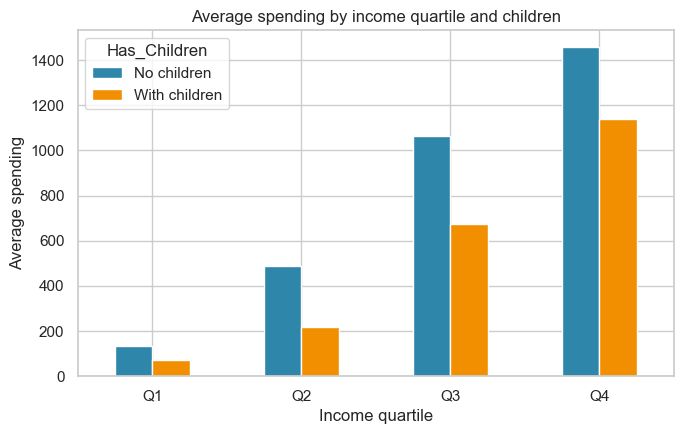

In [9]:
income_bins = pd.qcut(df["Income"].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
spend_by_income_children = df.assign(Income_Quartile=income_bins).groupby(
    ["Income_Quartile", "Has_Children"], observed=True
)["Total_Spending"].mean().unstack()

display(spend_by_income_children.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
spend_by_income_children.plot(kind="bar", ax=ax, color=["#2E86AB", "#F18F01"])
ax.set_title("Average spending by income quartile and children")
ax.set_xlabel("Income quartile")
ax.set_ylabel("Average spending")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
fig.savefig(ASSET_DIR / "04_income_children_spend.png", dpi=180, bbox_inches="tight")
plt.show()


The income split is a sanity check. The parent insight should not be oversold: income explains most of the value gap. The channel shift still matters because it tells the marketing team how to reach those households.


## Task C - RFM calculation and heuristic segmentation

RFM is built in the standard way: each customer receives a Recency, Frequency and Monetary score. I keep the additive score because it is transparent, then I add a pattern-based check to avoid hiding lapsed high-value customers.


In [10]:
# Frequency uses the three channel counts. NumDealsPurchases is not added because it is a discount attribute,
# not a separate channel. Adding it would double count many transactions.
df["R_Score"] = pd.qcut(df["Recency"].rank(method="first"), 5, labels=range(5, 0, -1)).astype(int)
df["F_Score"] = pd.qcut(df["Frequency"].rank(method="first"), 5, labels=range(1, 6)).astype(int)
df["M_Score"] = pd.qcut(df["Total_Spending"].rank(method="first"), 5, labels=range(1, 6)).astype(int)

df["RFM_Segment"] = df["R_Score"].astype(str) + df["F_Score"].astype(str) + df["M_Score"].astype(str)
df["RFM_Score"] = df["R_Score"] + df["F_Score"] + df["M_Score"]

def additive_segment(score):
    if score >= 13:
        return "Champions"
    if score >= 10:
        return "Loyal Customers"
    if score >= 6:
        return "Needs Attention"
    return "At Risk"

df["RFM_Additive_Segment"] = df["RFM_Score"].apply(additive_segment)

rfm_additive_summary = df.groupby("RFM_Additive_Segment").agg(
    customers=("RFM_Score", "size"),
    avg_recency=("Recency", "mean"),
    avg_frequency=("Frequency", "mean"),
    avg_spending=("Total_Spending", "mean"),
    revenue=("Total_Spending", "sum")
).sort_values("revenue", ascending=False)

display(df[["Recency", "Frequency", "Total_Spending", "R_Score", "F_Score", "M_Score", "RFM_Score", "RFM_Additive_Segment"]].head())
display(rfm_additive_summary.round(1))


,Recency,Frequency,Total_Spending,R_Score,F_Score,M_Score,RFM_Score,RFM_Additive_Segment
ID,,,,,,,,
5524,58,22,1617,3,5,5,13,Champions
2174,38,4,27,4,1,1,6,Needs Attention
4141,26,20,776,4,4,4,12,Loyal Customers
6182,26,6,53,4,2,1,7,Needs Attention
5324,94,14,422,1,3,3,7,Needs Attention


,customers,avg_recency,avg_frequency,avg_spending,revenue
RFM_Additive_Segment,,,,,
Loyal Customers,629,50.90,17.60,988.20,621609
Champions,311,21.80,21.30,"1,341.60",417226
Needs Attention,791,47.60,8.40,241.90,191332
At Risk,326,74.40,4.60,53.30,17387


,customers,revenue,revenue_share,avg_recency,avg_frequency,avg_spending
RFM_Pattern_Segment,,,,,,
Can't Lose Them,293,370018,0.30,78.99,20.57,"1,262.86"
Champions,284,353152,0.28,18.81,20.75,"1,243.49"
High Value Monitor,246,305895,0.24,50.01,17.26,"1,243.48"
Core / Monitor,587,174438,0.14,48.19,10.74,297.17
At Risk / Lost,319,22320,0.02,79.72,5.17,69.97
Promising / New,328,21731,0.02,18.97,5.05,66.25


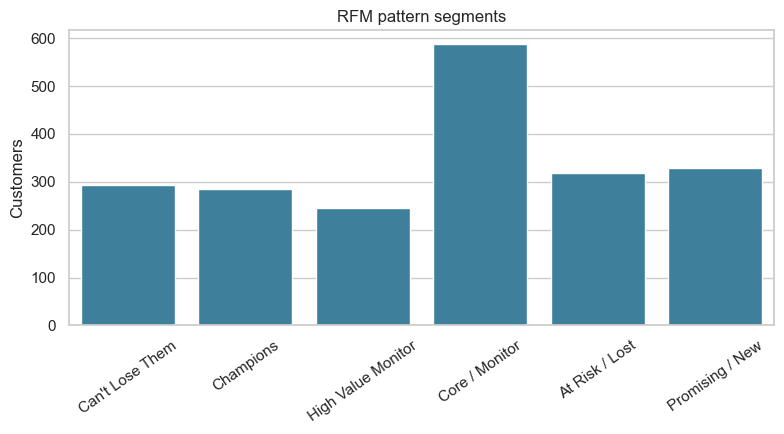

In [11]:
def rfm_pattern(row):
    r, f, m = row["R_Score"], row["F_Score"], row["M_Score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if r <= 2 and f >= 4 and m >= 4:
        return "Can't Lose Them"
    if r >= 4 and m <= 2:
        return "Promising / New"
    if r <= 2 and m <= 2:
        return "At Risk / Lost"
    if m >= 4:
        return "High Value Monitor"
    return "Core / Monitor"

df["RFM_Pattern_Segment"] = df.apply(rfm_pattern, axis=1)

rfm_pattern_summary = df.groupby("RFM_Pattern_Segment").agg(
    customers=("RFM_Score", "size"),
    revenue=("Total_Spending", "sum"),
    revenue_share=("Total_Spending", lambda s: s.sum() / df["Total_Spending"].sum()),
    avg_recency=("Recency", "mean"),
    avg_frequency=("Frequency", "mean"),
    avg_spending=("Total_Spending", "mean")
).sort_values("revenue", ascending=False)

display(rfm_pattern_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
order = rfm_pattern_summary.index
sns.barplot(data=rfm_pattern_summary.reset_index(), x="RFM_Pattern_Segment", y="customers", order=order, ax=ax, color="#2E86AB")
ax.set_title("RFM pattern segments")
ax.set_xlabel("")
ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
fig.savefig(ASSET_DIR / "05_rfm_pattern_segments.png", dpi=180, bbox_inches="tight")
plt.show()


The additive RFM score is useful, but it can hide a lapsed high-value customer: low Recency is compensated by high Frequency and Monetary. The pattern-based RFM table is the first warning that a win-back segment exists before clustering is even applied.


## Task D - K-Means cluster analysis

The clustering model uses the RFM variables only: `Recency`, `Frequency`, and `Total_Spending`. This is deliberate. The segment should be based on behaviour; demographics are used afterwards to profile the segment.

`Total_Spending` is log-transformed because it is right-skewed. Then all variables are standardised because K-Means is distance-based.


,k,inertia,silhouette
0,2,"3,007.34",0.45
1,3,"2,107.82",0.41
2,4,"1,463.88",0.40
3,5,"1,233.53",0.39
4,6,"1,058.12",0.35
5,7,934.52,0.33


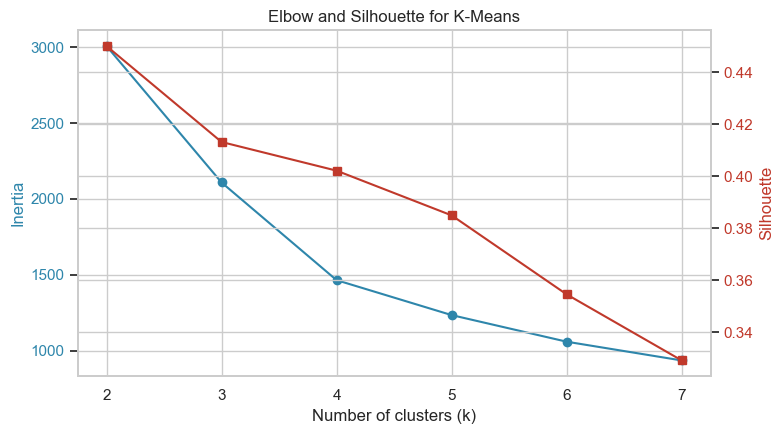

In [12]:
cluster_features = ["Recency", "Frequency", "Total_Spending"]
X = df[cluster_features].copy()
X["Total_Spending"] = np.log1p(X["Total_Spending"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_rows = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    k_rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })

k_eval = pd.DataFrame(k_rows)
display(k_eval.round(3))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(k_eval["k"], k_eval["inertia"], marker="o", color="#2E86AB")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia", color="#2E86AB")
ax1.tick_params(axis="y", labelcolor="#2E86AB")

ax2 = ax1.twinx()
ax2.plot(k_eval["k"], k_eval["silhouette"], marker="s", color="#C0392B")
ax2.set_ylabel("Silhouette", color="#C0392B")
ax2.tick_params(axis="y", labelcolor="#C0392B")

ax1.set_title("Elbow and Silhouette for K-Means")
plt.tight_layout()
fig.savefig(ASSET_DIR / "06_elbow_silhouette.png", dpi=180, bbox_inches="tight")
plt.show()


Silhouette is highest at k=2, which mainly splits high-value from low-value customers. For marketing, that is too coarse. k=4 keeps a good Silhouette and gives the minimum useful action map: recent/lapsed crossed with high/low value. This is a business choice, not a purely mechanical maximum-Silhouette choice.


In [13]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_profile = df.groupby("Cluster").agg(
    customers=("Cluster", "size"),
    revenue=("Total_Spending", "sum"),
    revenue_share=("Total_Spending", lambda s: s.sum() / df["Total_Spending"].sum()),
    recency=("Recency", "mean"),
    frequency=("Frequency", "mean"),
    monetary=("Total_Spending", "mean"),
    age=("Age", "mean"),
    income=("Income", "mean"),
    children=("Total_Children", "mean"),
    web=("NumWebPurchases", "mean"),
    catalog=("NumCatalogPurchases", "mean"),
    store=("NumStorePurchases", "mean"),
    response_rate=("Response", "mean")
).round(3)

# Attach human-readable labels using the centroid profile, not the arbitrary cluster number.
median_monetary = cluster_profile["monetary"].median()
median_recency = cluster_profile["recency"].median()

def persona_from_row(row):
    high_value = row["monetary"] >= median_monetary
    recent = row["recency"] <= median_recency
    if high_value and recent:
        return "Active Champions"
    if high_value and not recent:
        return "Can't Lose Them"
    if not high_value and recent:
        return "Promising / New"
    return "At Risk / Lost"

cluster_profile["persona"] = cluster_profile.apply(persona_from_row, axis=1)
persona_map = cluster_profile["persona"].to_dict()
df["Cluster_Persona"] = df["Cluster"].map(persona_map)

cluster_profile = cluster_profile.sort_values("persona")
display(cluster_profile)
cluster_profile.to_csv(ASSET_DIR / "T1_cluster_profile.csv")


,customers,revenue,revenue_share,recency,frequency,monetary,age,income,children,web,catalog,store,response_rate,persona
Cluster,,,,,,,,,,,,,,
0,560,562708,0.45,22.96,18.05,"1,004.84",46.50,"65,692.59",0.69,5.87,4.31,7.86,0.27,Active Champions
2,472,50096,0.04,74.25,6.07,106.14,43.75,"36,489.97",1.31,2.16,0.60,3.31,0.04,At Risk / Lost
3,561,598667,0.48,73.59,18.41,"1,067.14",47.68,"66,477.16",0.70,5.79,4.59,8.04,0.14,Can't Lose Them
1,464,36083,0.03,24.87,5.34,77.77,41.73,"34,005.23",1.22,1.89,0.43,3.02,0.14,Promising / New


,customers,customer_share,revenue,revenue_share,recency,frequency,monetary,income,children,response_rate
Cluster_Persona,,,,,,,,,,
Can't Lose Them,561,0.27,598667,0.48,73.59,18.41,"1,067.14","66,477.16",0.70,0.14
Active Champions,560,0.27,562708,0.45,22.96,18.05,"1,004.84","65,692.59",0.69,0.27
At Risk / Lost,472,0.23,50096,0.04,74.25,6.07,106.14,"36,489.97",1.31,0.04
Promising / New,464,0.23,36083,0.03,24.87,5.34,77.77,"34,005.23",1.22,0.14


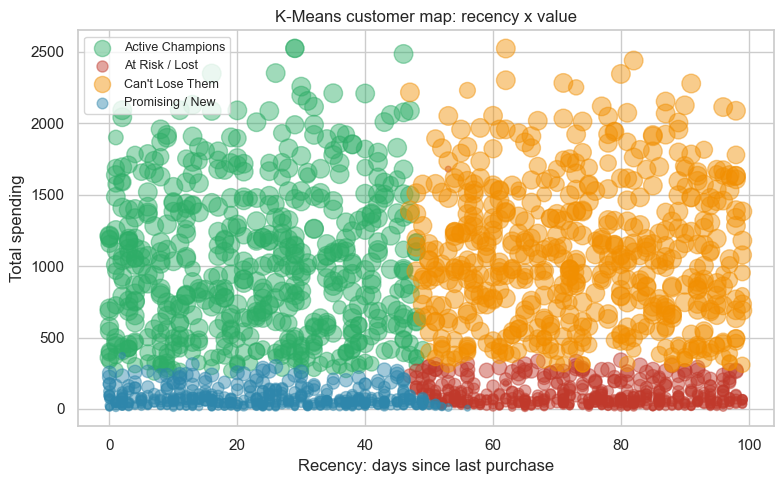

In [14]:
cluster_persona_summary = df.groupby("Cluster_Persona").agg(
    customers=("Cluster_Persona", "size"),
    customer_share=("Cluster_Persona", lambda s: len(s) / len(df)),
    revenue=("Total_Spending", "sum"),
    revenue_share=("Total_Spending", lambda s: s.sum() / df["Total_Spending"].sum()),
    recency=("Recency", "mean"),
    frequency=("Frequency", "mean"),
    monetary=("Total_Spending", "mean"),
    income=("Income", "mean"),
    children=("Total_Children", "mean"),
    response_rate=("Response", "mean")
).round(3).sort_values("revenue", ascending=False)

display(cluster_persona_summary)
cluster_persona_summary.to_csv(ASSET_DIR / "T2_persona_summary.csv")

fig, ax = plt.subplots(figsize=(8, 5))
colors = {
    "Active Champions": "#2EAD67",
    "Can't Lose Them": "#F18F01",
    "Promising / New": "#2E86AB",
    "At Risk / Lost": "#C0392B"
}
for persona, sub in df.groupby("Cluster_Persona"):
    ax.scatter(sub["Recency"], sub["Total_Spending"], s=np.clip(sub["Frequency"] * 10, 18, 180),
               alpha=0.45, label=persona, color=colors.get(persona))
ax.set_title("K-Means customer map: recency x value")
ax.set_xlabel("Recency: days since last purchase")
ax.set_ylabel("Total spending")
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
fig.savefig(ASSET_DIR / "07_cluster_map.png", dpi=180, bbox_inches="tight")
plt.show()


RFM_Additive_Segment,At Risk,Champions,Loyal Customers,Needs Attention
Cluster_Persona,,,,
Active Champions,0,284,260,16
At Risk / Lost,274,0,0,198
Can't Lose Them,0,27,343,191
Promising / New,52,0,26,386


RFM_Pattern_Segment,At Risk / Lost,Can't Lose Them,Champions,Core / Monitor,High Value Monitor,Promising / New
Cluster_Persona,,,,,,
Active Champions,0,0,284,171,105,0
At Risk / Lost,319,0,0,152,1,0
Can't Lose Them,0,293,0,128,140,0
Promising / New,0,0,0,136,0,328


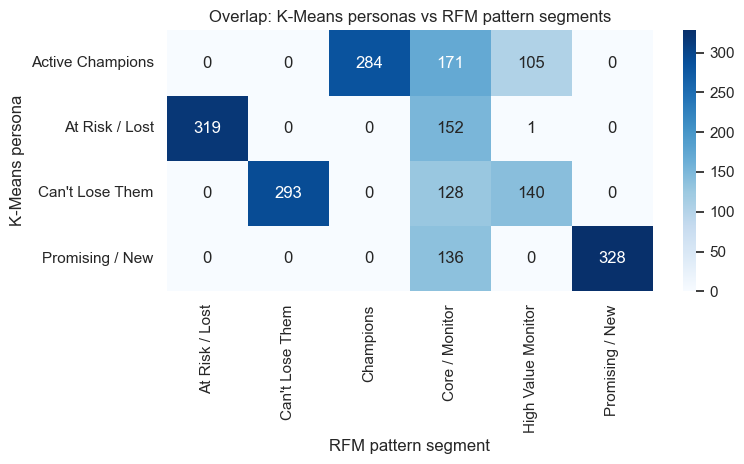

In [15]:
ct_additive = pd.crosstab(df["Cluster_Persona"], df["RFM_Additive_Segment"])
ct_pattern = pd.crosstab(df["Cluster_Persona"], df["RFM_Pattern_Segment"])

display(ct_additive)
display(ct_pattern)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(ct_pattern, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Overlap: K-Means personas vs RFM pattern segments")
ax.set_xlabel("RFM pattern segment")
ax.set_ylabel("K-Means persona")
plt.tight_layout()
fig.savefig(ASSET_DIR / "08_cluster_rfm_overlap.png", dpi=180, bbox_inches="tight")
plt.show()

ct_additive.to_csv(ASSET_DIR / "T3_cluster_vs_additive_rfm.csv")
ct_pattern.to_csv(ASSET_DIR / "T4_cluster_vs_pattern_rfm.csv")


### Robustness checks

The key modelling decision is whether to define clusters on RFM behaviour only or to add channels and demographics. I test the alternatives explicitly. The final choice remains RFM-only because it gives the cleanest separation and the most interpretable action map; channels are then used for profiling and communication, not for defining the cluster boundaries.

In [16]:
def evaluate_feature_set(name, feature_list, log_spending=True):
    X_tmp = df[feature_list].copy()
    if log_spending and "Total_Spending" in X_tmp.columns:
        X_tmp["Total_Spending"] = np.log1p(X_tmp["Total_Spending"])
    X_tmp = StandardScaler().fit_transform(X_tmp)
    out = []
    for k in range(2, 8):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(X_tmp)
        out.append({"feature_set": name, "k": k, "silhouette": silhouette_score(X_tmp, labels)})
    return pd.DataFrame(out)

campaign_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response", "Complain"]
feature_sets = {
    "RFM only": ["Recency", "Frequency", "Total_Spending"],
    "RFM + channels": ["Recency", "Frequency", "Total_Spending", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumDealsPurchases", "NumWebVisitsMonth"],
    "RFM + demographics": ["Recency", "Frequency", "Total_Spending", "Age", "Income"],
    "Full behaviour": ["Recency", "Frequency", "Total_Spending", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumDealsPurchases", "NumWebVisitsMonth", *campaign_cols],
}

sensitivity = pd.concat(
    [evaluate_feature_set(name, features) for name, features in feature_sets.items()],
    ignore_index=True,
)

sensitivity_pivot = sensitivity.pivot(index="k", columns="feature_set", values="silhouette")
display(sensitivity_pivot.round(3))

display(
    sensitivity[sensitivity["k"] == 4]
    .sort_values("silhouette", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

sensitivity.to_csv(ASSET_DIR / "T5_sensitivity_silhouette.csv", index=False)


feature_set,Full behaviour,RFM + channels,RFM + demographics,RFM only
k,,,,
2,0.26,0.36,0.37,0.45
3,0.26,0.32,0.29,0.41
4,0.28,0.28,0.24,0.40
5,0.29,0.21,0.24,0.39
6,0.28,0.21,0.24,0.35
7,0.29,0.20,0.24,0.33


,feature_set,k,silhouette
0,RFM only,4,0.40
1,RFM + channels,4,0.28
2,Full behaviour,4,0.28
3,RFM + demographics,4,0.24


The sensitivity check supports the modelling choice. Adding channels or demographics lowers cluster separation at k=4, so I keep the RFM-only K-Means as the segmentation backbone. This does not mean channel variables are irrelevant: they are more useful after clustering, when translating personas into channel strategy and campaign execution.

## Task E - Communication strategy

The strategy below translates the segmentation into channel, message and measurement. The measurement column is important: a campaign is not complete until the marketing team knows how it will judge success.


In [17]:
strategy = pd.DataFrame([
    {
        "Segment": "Active Champions",
        "Priority": "Protect value",
        "Channel": "Email, web, loyalty area",
        "Message": "VIP recognition, early access, premium bundles. Avoid broad discounts.",
        "Measurement": "Holdout group; repeat purchase rate and incremental revenue."
    },
    {
        "Segment": "Can't Lose Them",
        "Priority": "First win-back target",
        "Channel": "Personal email plus direct mail or phone for top spenders",
        "Message": "Personal win-back with a meaningful incentive and premium framing.",
        "Measurement": "Target/control test; response rate, recovered revenue and ROI."
    },
    {
        "Segment": "Promising / New",
        "Priority": "Build habit",
        "Channel": "Email and web onboarding",
        "Message": "Second-purchase nudge, recommendations and simple bundles.",
        "Measurement": "Second-purchase conversion within 30/60 days."
    },
    {
        "Segment": "At Risk / Lost",
        "Priority": "Low-cost reactivation",
        "Channel": "Automated email and in-store deals",
        "Message": "Value-oriented offer with capped budget.",
        "Measurement": "Reactivate only if margin-positive versus control."
    }
])

display(strategy)
strategy.to_csv(ASSET_DIR / "T6_communication_strategy.csv", index=False)


,Segment,Priority,Channel,Message,Measurement
0,Active Champions,Protect value,"Email, web, loyalty area","VIP recognition, early access, premium bundles...",Holdout group; repeat purchase rate and increm...
1,Can't Lose Them,First win-back target,Personal email plus direct mail or phone for t...,Personal win-back with a meaningful incentive ...,"Target/control test; response rate, recovered ..."
2,Promising / New,Build habit,Email and web onboarding,"Second-purchase nudge, recommendations and sim...",Second-purchase conversion within 30/60 days.
3,At Risk / Lost,Low-cost reactivation,Automated email and in-store deals,Value-oriented offer with capped budget.,Reactivate only if margin-positive versus cont...


In [18]:
# Compact numbers for the stakeholder slides.
slide_metrics = {
    "clean_customers": int(len(df)),
    "total_revenue": int(df["Total_Spending"].sum()),
    "income_spend_spearman": float(corr_spearman.loc["Income", "Total_Spending"]),
    "kidhome_spend_spearman": float(corr_spearman.loc["Kidhome", "Total_Spending"]),
    "catalog_drop_children_0_to_3": float(catalog_drop),
    "web_drop_children_0_to_3": float(web_drop),
}

for persona in ["Active Champions", "Can't Lose Them", "Promising / New", "At Risk / Lost"]:
    row = cluster_persona_summary.loc[persona]
    key = persona.lower().replace(" ", "_").replace("/", "").replace("'", "").replace("__", "_")
    slide_metrics[f"{key}_customers"] = int(row["customers"])
    slide_metrics[f"{key}_revenue"] = int(row["revenue"])
    slide_metrics[f"{key}_revenue_share"] = float(row["revenue_share"])
    slide_metrics[f"{key}_recency"] = float(row["recency"])

pd.Series(slide_metrics).to_csv(ASSET_DIR / "T7_slide_metrics.csv")
display(pd.Series(slide_metrics).rename("value").to_frame())


,value
clean_customers,"2,057.00"
total_revenue,"1,247,554.00"
income_spend_spearman,0.85
kidhome_spend_spearman,-0.62
catalog_drop_children_0_to_3,0.78
web_drop_children_0_to_3,0.39
active_champions_customers,560.00
active_champions_revenue,"562,708.00"
active_champions_revenue_share,0.45
active_champions_recency,22.96


## Final reading

The most important segment is Can't Lose Them: high-frequency, high-spending customers who are no longer recent. RFM already contains this signal, but a simple additive score can blur it. K-Means on the RFM variables makes the Recency x Value structure easier to act on.

The campaign recommendation is therefore not broad discounting. The first action should be a measured win-back test on the lapsed high-value segment, with a control group and ROI calculation.
